# SafeStair — Dynamic Programming
**Challenge Motiva + FIAP 2026/2027 · Engenharia de Software · Turma 2ESPR · Squad 6**

| Integrante | RM |
|---|---|
| Marcelo Checchia Pivello de Toledo | 538697 |
| Nícolas Miguel Bittencourt Tanajura | 568108 |
| Rafael Benez Martins | 574994 |

Este notebook implementa a camada algorítmica do SafeStair sobre o **dataset real da Motiva**: o histórico de notas de manutenção (SAP) das escadas rolantes da Linha 4-Amarela, de 2009 a 2026.

1. **Degradação acumulada** de cada escada, mês a mês, em três versões (recursiva pura, memoizada com dicionário e iterativa com tabulação), com medição e **ranking por criticidade**.
2. **Rede de estações como grafo** (lista de adjacência), com **BFS** (menos trechos) e **Dijkstra** (menor tempo) a partir da base de manutenção, reconstruindo as rotas.
3. **Otimização de rotas com A\***, com heurística justificada e comparação com o Dijkstra.
4. **Plano de manutenção** `planejar_turno(base, horas)`: quais escadas atender, em que ordem e por qual caminho.

Os arquivos em `data/` são gerados por `scripts/preparar_dados.py` (a partir das planilhas `ecr_AAAA.XLSX`) e `scripts/gerar_rede.py`.

> **Notebook complementar:** `notebook_sensores.ipynb` aplica os mesmos algoritmos a leituras de sensores simuladas (vibração, temperatura, corrente/tensão, óleo, velocidade), o tipo de dado que o SafeStair propõe coletar, usando os mesmos limites do `ManutencaoService` (DDD-Java).

In [1]:
import sys, json, math, time, heapq, random
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

sys.setrecursionlimit(20_000)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

DADOS = Path("data")
FIGURAS = Path("figuras"); FIGURAS.mkdir(exist_ok=True)

falhas = pd.read_csv(DADOS / "falhas.csv", parse_dates=["inicio", "fim"])
escadas = pd.read_csv(DADOS / "escadas.csv")
resumo_anos = pd.read_csv(DADOS / "resumo_notas_ano.csv").set_index("ano_arquivo")
rede = json.loads((DADOS / "rede_estacoes.json").read_text(encoding="utf-8"))
nomes_est = {v["id"]: v["nome"] for v in rede["vertices"]}

print(f"Falhas (Z1): {len(falhas)} · {falhas.cd_escada.nunique()} escadas · "
      f"{falhas.inicio.min():%d/%m/%Y} a {falhas.inicio.max():%d/%m/%Y}")
print(f"Escadas: {len(escadas)} em {escadas.id_estacao.nunique()} locais · "
      f"rede: {len(rede['vertices'])} vértices, {len(rede['arestas'])} arestas")
falhas.head()

Falhas (Z1): 27200 · 197 escadas · 01/01/2023 a 31/08/2026
Escadas: 197 em 12 locais · rede: 20 vértices, 22 arestas


,nota,cd_escada,id_estacao,inicio,fim,horas_parada,indisponivel,substituicao,sintoma,defeito,causa,componente,acao
0,13067411,BUT-ER01,BUT,2023-01-19 17:19:00,2023-01-20 11:21:48,18.047,1,1,INOPERANTE,DESGASTADO(A),ENVELHECIMENTO,ACOPLAMENTO,SUBSTITUIDO(A)
1,13143656,BUT-ER01,BUT,2023-03-03 07:15:00,2023-03-03 08:15:06,1.002,1,0,ALARME-LINHA DE SEGURANCA,FORA DE AJUSTE,FOLGA ANORMAL,PAINEL SUP,APERTADO(A)
2,13174104,BUT-ER01,BUT,2023-03-20 16:31:05,2023-03-20 16:45:13,0.236,1,0,INOPERANTE,SUBTENSAO,FIXACAO FORA DE POSICAO,CABEAMENTO,RESETADO E TESTADO
3,13209040,BUT-ER01,BUT,2023-04-09 10:52:40,2023-04-09 11:00:33,0.131,1,0,INOPERANTE,FORA DE AJUSTE,FIXACAO FORA DE POSICAO,BASE APOIO,AJUSTADO(A)
4,13225848,BUT-ER01,BUT,2023-04-18 19:13:46,2023-04-18 19:18:40,0.082,1,0,INOPERANTE,MAU CONTATO,FORA DOS LIMITES,PLACA PENTE MOVEL,RESETADO E TESTADO


### 0. O que é o dataset e por que o recorte 2023–2026

Cada linha das planilhas é uma **nota de manutenção** do SAP. Os tipos mais frequentes:

| Tipo | O que representa |
|---|---|
| Z1 | Falha corretiva (a escada parou ou deu alarme) |
| Z2 | Anomalia percebida sem parada (ruído, folga, óleo baixo) |
| Z3 | Preventiva programada (planos P1, P6…) |

O campo **Local de Instalação** identifica a escada (`SP04-6-ECR-PIN-ER24` = Linha 4, Pinheiros, escada ER24); dele vêm o código da escada e da estação. Usamos as **falhas Z1**, porque são elas que medem a degradação real do equipamento.

In [2]:
display(resumo_anos[["Z1", "Z2", "Z3"]].T)

ano_arquivo,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Z1,6,123,2647,1696,1098,1077,1099,1205,971,1242,1387,1041,1441,1994,7563,8559,7805,6326
Z2,4,144,258,421,527,634,992,1063,538,1167,1915,1789,1794,2061,2187,2241,2149,1959
Z3,24774,251,776,1296,1294,1245,1295,926,195,221,337,171,114,280,155,66,119,88


**Interpretação do recorte.** O volume de falhas Z1 salta de cerca de 2 mil para mais de 7 mil por ano em 2023. Não é a frota quebrando mais: a partir de 2023 cerca de 78% das falhas passam a ser abertas automaticamente pelo monitoramento (status OAUT, descrição "Falha Técnica"). Misturar os dois regimes faria toda escada parecer piorar em 2023. Por isso a análise usa **jan/2023 a ago/2026** (44 meses completos; o arquivo de 2026 termina em 22/09), e o arquivo de 2009, que é quase todo carga do plano preventivo (Z3), fica de fora. Também foram excluídas notas canceladas ou duplicadas.

---
## Parte 1 — Degradação acumulada (recursão, memoização e tabulação)

### 1.1 Penalidade de cada falha e de cada mês

Cada falha recebe um peso em pontos:

$$\text{peso} = \underbrace{b}_{\text{1 se parou a escada, 0,5 se não}} \times \underbrace{f}_{\text{1,5 se houve troca de peça}} + \frac{\min(\text{horas parada},\ 72)}{4}$$

- A **troca de peça** indica desgaste físico, mais grave que um reset (44% das falhas se resolvem com "RESETADO E TESTADO").
- Cada **4 horas de parada** valem 1 ponto, com teto de 72 h por falha para que um único evento extremo (há paradas de mais de 30 dias) não domine a série.

A **penalidade do mês** $p_i$ de uma escada é a soma dos pesos das falhas que começaram naquele mês. O resultado é uma série de 44 valores por escada.

In [3]:
falhas["peso"] = (np.where(falhas.indisponivel == 1, 1.0, 0.5) * np.where(falhas.substituicao == 1, 1.5, 1.0)
                  + falhas.horas_parada.clip(0, 72).fillna(0) / 4)
falhas["mes"] = falhas.inicio.dt.to_period("M")
MESES = pd.period_range("2023-01", "2026-08", freq="M")

P = (falhas.pivot_table(index="cd_escada", columns="mes", values="peso", aggfunc="sum", fill_value=0)
           .reindex(index=escadas.cd_escada, columns=MESES, fill_value=0))
series_p = {cd: P.loc[cd].tolist() for cd in P.index}

print(f"Matriz de penalidades: {P.shape[0]} escadas × {P.shape[1]} meses")
print("Penalidade mensal (pontos):", pd.Series(P.values.ravel()).describe(percentiles=[.5, .9, .99]).round(1).to_dict())
P.sum(axis=1).sort_values(ascending=False).head(5).round(1).rename("penalidade total 44 meses")

Matriz de penalidades: 197 escadas × 44 meses
Penalidade mensal (pontos): {'count': 8668.0, 'mean': 4.7, 'std': 6.3, 'min': 0.0, '50%': 2.5, '90%': 11.8, '99%': 29.6, 'max': 69.7}


cd_escada
PIN-ER24    725.7
PIN-ER14    666.5
PIN-ER21    609.2
LUZ-ER02    555.3
LUZ-ER04    528.2
Name: penalidade total 44 meses, dtype: float64

### 1.2 Recorrência da degradação acumulada

Desgaste acumula e, quando está acelerando, merece ainda mais atenção. Definimos, mês a mês:

$$
D(0) = p_0, \qquad D(1) = p_1 + \alpha\,D(0)
$$
$$
D(i) = p_i + \alpha\,D(i-1) + \beta\,\max\bigl(0,\ D(i-1) - D(i-2)\bigr), \quad i \ge 2
$$

- $\alpha = 0{,}85$ é a **memória**: o histórico pesa, mas perde 15% por mês. Depois de 12 meses resta só $0{,}85^{12} \approx 14\%$, então $D$ reflete principalmente o último ano.
- $\beta = 0{,}5$ é o **termo de aceleração**: se a degradação subiu do mês $i-2$ para o $i-1$, metade desse aumento é somada. Uma escada piorando passa à frente de outra com o mesmo nível estável.

Como $D(i)$ depende de $D(i-1)$ **e** de $D(i-2)$, a recursão pura recalcula os mesmos subproblemas várias vezes, como na sequência de Fibonacci.

In [4]:
ALFA, BETA = 0.85, 0.5


def degradacao_recursiva(p, i, contador=None):
    """Versão 1 — recursiva pura. Complexidade O(φ^n) chamadas (φ ≈ 1,618).

    Args:
        p (list[float]): penalidades mensais, em ordem cronológica.
        i (int): índice do mês cuja degradação acumulada se quer.
        contador (list[int], opcional): contador de chamadas, para medição.

    Returns:
        float: D(i).
    """
    if contador is not None:
        contador[0] += 1
    if i == 0:
        return p[0]
    if i == 1:
        return p[1] + ALFA * degradacao_recursiva(p, 0, contador)
    d1 = degradacao_recursiva(p, i - 1, contador)
    d2 = degradacao_recursiva(p, i - 2, contador)
    return p[i] + ALFA * d1 + BETA * max(0.0, d1 - d2)


def degradacao_memo(p, i, memo=None, contador=None):
    """Versão 2 — recursiva com memoização em dicionário. O(n) tempo e memória.

    Args:
        p (list[float]): penalidades mensais.
        i (int): índice do mês.
        memo (dict[int, float], opcional): cache {índice: D(índice)}.
        contador (list[int], opcional): contador de chamadas.

    Returns:
        float: D(i).
    """
    if memo is None:
        memo = {}
    if contador is not None:
        contador[0] += 1
    if i in memo:
        return memo[i]
    if i == 0:
        valor = p[0]
    elif i == 1:
        valor = p[1] + ALFA * degradacao_memo(p, 0, memo, contador)
    else:
        d1 = degradacao_memo(p, i - 1, memo, contador)
        d2 = degradacao_memo(p, i - 2, memo, contador)
        valor = p[i] + ALFA * d1 + BETA * max(0.0, d1 - d2)
    memo[i] = valor
    return valor


def degradacao_tabulacao(p):
    """Versão 3 — iterativa com tabulação (bottom-up). O(n) tempo, sem pilha de recursão.

    Args:
        p (list[float]): penalidades mensais.

    Returns:
        list[float]: a série completa D(0), D(1), ..., D(n-1).
    """
    n = len(p)
    tabela = [0.0] * n
    tabela[0] = p[0]
    if n > 1:
        tabela[1] = p[1] + ALFA * tabela[0]
    for i in range(2, n):
        tabela[i] = p[i] + ALFA * tabela[i - 1] + BETA * max(0.0, tabela[i - 1] - tabela[i - 2])
    return tabela

### 1.3 As três versões dão o mesmo resultado?

A série completa tem 44 meses, longa demais para a recursão pura (estimamos o custo abaixo). Por isso a comparação das **três** versões é feita nos **últimos 24 meses** de cada uma das 197 escadas; memoizada e tabulação também são comparadas na série completa.

In [5]:
JANELA = 24
linhas = []
for cd, p_total in series_p.items():
    p = p_total[-JANELA:]
    c_rec, c_memo = [0], [0]
    t0 = time.perf_counter(); d_rec = degradacao_recursiva(p, JANELA - 1, c_rec); t_rec = time.perf_counter() - t0
    t0 = time.perf_counter(); d_memo = degradacao_memo(p, JANELA - 1, {}, c_memo); t_memo = time.perf_counter() - t0
    t0 = time.perf_counter(); d_tab = degradacao_tabulacao(p)[-1]; t_tab = time.perf_counter() - t0
    linhas.append({"cd_escada": cd, "D_rec": d_rec, "D_memo": d_memo, "D_tab": d_tab,
                   "chamadas_rec": c_rec[0], "chamadas_memo": c_memo[0],
                   "ms_rec": 1e3 * t_rec, "ms_memo": 1e3 * t_memo, "ms_tab": 1e3 * t_tab})
comparacao = pd.DataFrame(linhas)

iguais_24 = np.allclose(comparacao.D_rec, comparacao.D_memo) and np.allclose(comparacao.D_memo, comparacao.D_tab)
iguais_44 = all(math.isclose(degradacao_memo(p, len(p) - 1, {}), degradacao_tabulacao(p)[-1]) for p in series_p.values())
print(f"Janela de {JANELA} meses — as três versões coincidem nas {len(comparacao)} escadas: {iguais_24}")
print(f"Série completa de {len(MESES)} meses — memoizada e tabulação coincidem: {iguais_44}")
print(f"Diferença máxima recursiva × tabulação: {np.max(np.abs(comparacao.D_rec - comparacao.D_tab)):.2e}\n")
tot = comparacao[["chamadas_rec", "chamadas_memo", "ms_rec", "ms_memo", "ms_tab"]].sum()
print(tot.round(1).to_string())

# Custo estimado da recursão pura na série completa: C(0)=1, C(1)=2, C(i)=1+C(i-1)+C(i-2)
C = [1, 2]
for i in range(2, len(MESES)):
    C.append(1 + C[-1] + C[-2])
us_por_chamada = 1e3 * tot.ms_rec / tot.chamadas_rec
estimativa_h = C[-1] * us_por_chamada / 1e6 / 3600
print(f"\nRecursão pura com {len(MESES)} meses: {C[-1]:,} chamadas por escada "
      f"≈ {estimativa_h * 60:.0f} min por escada ≈ {estimativa_h * len(series_p):.0f} h para as {len(series_p)} escadas")

Janela de 24 meses — as três versões coincidem nas 197 escadas: True
Série completa de 44 meses — memoizada e tabulação coincidem: True
Diferença máxima recursiva × tabulação: 0.00e+00

chamadas_rec     23914224.0
chamadas_memo        9062.0
ms_rec               4139.4
ms_memo                 3.7
ms_tab                  2.0

Recursão pura com 44 meses: 1,836,311,902 chamadas por escada ≈ 5 min por escada ≈ 17 h para as 197 escadas


### 1.4 Medição: como o custo cresce com o tamanho da série

Usamos séries de tamanho $n$ crescente sorteadas (com reposição) das penalidades mensais reais. Cada tempo é a mediana de várias execuções. A recursão pura vai só até $n = 28$; memoizada e tabulação vão até 5 000 meses, para mostrar o comportamento linear.

,n,chamadas_rec,chamadas_memo,ms_rec,ms_memo,ms_tab
0,5,1.200000e+01,8,0.0039,0.0025,0.0021
1,10,1.430000e+02,18,0.0342,0.0059,0.0045
2,15,1.596000e+03,28,0.3422,0.0077,0.0059
3,20,1.771000e+04,38,3.9563,0.0106,0.0076
4,22,4.636700e+04,42,10.5165,0.0124,0.0088
5,24,1.213920e+05,46,27.3037,0.0133,0.0094
6,26,3.178100e+05,50,70.6028,0.0145,0.0101
7,28,8.320390e+05,54,182.4374,0.0149,0.0108
8,44,1.836312e+09,86,NaN,0.0247,0.0193
9,100,NaN,198,NaN,0.0684,0.0393


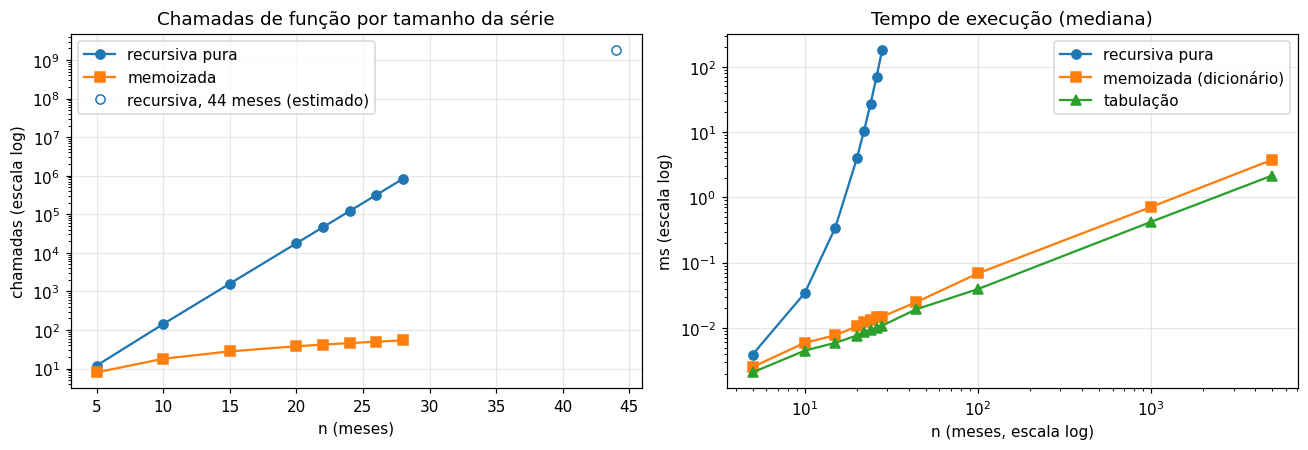

Crescimento das chamadas da recursiva a cada +2 meses: [2.618 2.618 2.618] (φ² ≈ 2,618)


In [6]:
def medir(func, repeticoes=5):
    """Mediana do tempo de execução (ms) de func() em algumas repetições."""
    tempos = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); func(); tempos.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(tempos))

rng = np.random.default_rng(7)
serie_longa = list(rng.choice(P.values.ravel(), size=6000, replace=True))

medicoes = []
for n in [5, 10, 15, 20, 22, 24, 26, 28]:
    p = serie_longa[:n]
    c = [0]; degradacao_recursiva(p, n - 1, c)
    cm = [0]; degradacao_memo(p, n - 1, {}, cm)
    medicoes.append({"n": n, "chamadas_rec": c[0], "chamadas_memo": cm[0],
                     "ms_rec": medir(lambda: degradacao_recursiva(p, n - 1), 3),
                     "ms_memo": medir(lambda: degradacao_memo(p, n - 1, {})),
                     "ms_tab": medir(lambda: degradacao_tabulacao(p))})
for n in [44, 100, 1000, 5000]:
    p = serie_longa[:n]
    cm = [0]; degradacao_memo(p, n - 1, {}, cm)
    medicoes.append({"n": n, "chamadas_rec": C[-1] if n == 44 else np.nan, "chamadas_memo": cm[0], "ms_rec": np.nan,
                     "ms_memo": medir(lambda: degradacao_memo(p, n - 1, {})),
                     "ms_tab": medir(lambda: degradacao_tabulacao(p))})
medicoes = pd.DataFrame(medicoes)
display(medicoes.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
m = medicoes.dropna(subset=["ms_rec"])
ax[0].semilogy(m.n, m.chamadas_rec, "o-", label="recursiva pura")
ax[0].semilogy(m.n, m.chamadas_memo, "s-", label="memoizada")
ax[0].semilogy([44], [C[-1]], "o", mfc="none", color="C0", label=f"recursiva, 44 meses (estimado)")
ax[0].set(title="Chamadas de função por tamanho da série", xlabel="n (meses)", ylabel="chamadas (escala log)")
ax[0].legend()
ax[1].loglog(medicoes.n, medicoes.ms_rec, "o-", label="recursiva pura")
ax[1].loglog(medicoes.n, medicoes.ms_memo, "s-", label="memoizada (dicionário)")
ax[1].loglog(medicoes.n, medicoes.ms_tab, "^-", label="tabulação")
ax[1].set(title="Tempo de execução (mediana)", xlabel="n (meses, escala log)", ylabel="ms (escala log)")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIGURAS / "tempo_degradacao.png", bbox_inches="tight"); plt.show()

razao = medicoes.dropna(subset=["ms_rec"]).set_index("n").chamadas_rec
print("Crescimento das chamadas da recursiva a cada +2 meses:",
      (razao.loc[[24, 26, 28]].values / razao.loc[[22, 24, 26]].values).round(3), "(φ² ≈ 2,618)")

**Interpretação.**

- **Resultados idênticos.** As três versões produzem o mesmo $D$ para as 197 escadas. Memoização e tabulação mudam **o custo**, não **a resposta**.
- **Recursiva pura é exponencial.** O número de chamadas multiplica-se por 2,618 a cada dois meses a mais, exatamente $\varphi^2$. Na janela de 24 meses já são 121 392 chamadas por escada (24 milhões nas 197 escadas, contra 9 062 da memoizada). Na série real de 44 meses seriam 1,8 bilhão de chamadas por escada: cerca de 7 minutos por escada e quase um dia inteiro para a frota.
- **Memoizada é linear** ($2n - 2$ chamadas: cada mês é calculado uma vez e consultado no dicionário uma vez), mas depende da pilha de recursão, cujo limite precisamos aumentar para séries longas.
- **Tabulação é linear, não usa pilha** e devolve a série inteira de $D$. Para séries longas ela também é mais rápida que a memoizada, que paga o custo das chamadas de função e das consultas ao dicionário. É a versão adotada no ranking e no restante do projeto.

### 1.5 Ranking das escadas por criticidade

A **criticidade** é a degradação acumulada no último mês (ago/2026), calculada pela tabulação sobre os 44 meses. Como $D$ não tem uma escala física, as classes são definidas pela **posição na frota**, o que transforma o ranking numa fila de atendimento:

| Classe | Posição no ranking das 197 escadas |
|---|---|
| Crítica | 5% com maior $D$ (9 escadas) |
| Alta | até 20% (30 escadas) |
| Média | até 50% (59 escadas) |
| Baixa | 50% restantes (99 escadas) |

A coluna `tendencia` compara $D$ de agosto/2026 com o de seis meses antes: mais de 20% acima é "piorando", mais de 20% abaixo é "melhorando".

In [7]:
serie_D = {cd: degradacao_tabulacao(p) for cd, p in series_p.items()}
ult12 = falhas[falhas.mes >= MESES[-12]]

ranking = pd.DataFrame({"cd_escada": list(serie_D), "criticidade": [s[-1] for s in serie_D.values()],
                        "D_6m_atras": [s[-7] for s in serie_D.values()]}).merge(escadas[["cd_escada", "id_estacao"]])
ranking["estacao"] = ranking.id_estacao.map(nomes_est)
ranking["falhas_12m"] = ranking.cd_escada.map(ult12.groupby("cd_escada").size()).fillna(0).astype(int)
ranking["horas_parada_12m"] = ranking.cd_escada.map(ult12.groupby("cd_escada").horas_parada.sum()).fillna(0).round(0)
ranking["componente_principal"] = ranking.cd_escada.map(
    ult12.dropna(subset=["componente"]).groupby("cd_escada").componente.agg(lambda s: s.value_counts().index[0])).fillna("—")
ranking["tendencia"] = np.where(ranking.criticidade > 1.2 * ranking.D_6m_atras, "piorando",
                                np.where(ranking.criticidade < 0.8 * ranking.D_6m_atras, "melhorando", "estável"))
ranking = ranking.sort_values("criticidade", ascending=False).reset_index(drop=True)
pct = (ranking.index + 1) / len(ranking)
ranking["classe"] = np.select([pct <= 0.05, pct <= 0.20, pct <= 0.50], ["Crítica", "Alta", "Média"], "Baixa")
ranking.index = ranking.index + 1
ranking.index.name = "posição"

colunas = ["cd_escada", "estacao", "criticidade", "classe", "tendencia", "falhas_12m", "horas_parada_12m", "componente_principal"]
display(ranking[colunas].head(20).round(1))
print(ranking.classe.value_counts().reindex(["Crítica", "Alta", "Média", "Baixa"]).to_string())

,cd_escada,estacao,criticidade,classe,tendencia,falhas_12m,horas_parada_12m,componente_principal
posição,,,,,,,,
1,PTA-ER15,Paulista,143.3,Crítica,piorando,75,532.0,PLACA PENTE MOVEL
2,PIN-ER24,Pinheiros,138.1,Crítica,estável,129,386.0,SENSOR DE PRESENCA-VELOCIDAD-CJ.MOTO-RED
3,PTA-ER17,Paulista,123.4,Crítica,estável,121,422.0,PENTE DA PLACA PENTE
4,PIN-ER28,Pinheiros,115.9,Crítica,estável,132,286.0,DISPOSITIVO DE SEGURANCA
5,PIN-ER21,Pinheiros,110.4,Crítica,estável,51,2466.0,RELE TERMICO
6,PIN-ER06,Pinheiros,108.7,Crítica,piorando,85,130.0,ROLETE PARA DEGRAU
7,LUZ-ER10,Luz,105.8,Crítica,piorando,69,270.0,ROLETE PARA DEGRAU
8,VSO-ER08,Vila Sônia,105.3,Crítica,piorando,133,245.0,CONTATO DE SEGURANCA
9,LUZ-ER11,Luz,104.2,Crítica,piorando,62,211.0,SENSOR DE PRESENCA


classe
Crítica     9
Alta       30
Média      59
Baixa      99


In [8]:
# O que a degradação acumulada acrescenta a uma simples contagem de falhas?
ranking["pos_D"] = ranking.index
ranking["pos_contagem"] = ranking.falhas_12m.rank(ascending=False, method="min").astype(int)
rho = ranking[["criticidade", "falhas_12m"]].corr(method="spearman").iloc[0, 1]
print(f"Correlação de Spearman entre D e falhas nos últimos 12 meses: {rho:.2f}")
top20_D, top20_cont = set(ranking.cd_escada.head(20)), set(ranking.nsmallest(20, "pos_contagem").cd_escada)
print(f"Escadas em comum no top 20 dos dois critérios: {len(top20_D & top20_cont)} de 20")
ranking["subiu"] = ranking.pos_contagem - ranking.pos_D
display(ranking.sort_values("subiu", ascending=False).head(5)[
    ["cd_escada", "pos_D", "pos_contagem", "falhas_12m", "horas_parada_12m", "tendencia"]])

Correlação de Spearman entre D e falhas nos últimos 12 meses: 0.89
Escadas em comum no top 20 dos dois critérios: 14 de 20


,cd_escada,pos_D,pos_contagem,falhas_12m,horas_parada_12m,tendencia
posição,,,,,,
18,PIN-ER15,18,128,25,3823.0,piorando
32,PIN-ER30,32,134,22,1670.0,melhorando
27,PIN-ER20,27,120,26,4587.0,estável
11,PIN-ER14,11,104,32,1882.0,melhorando
36,FAL-ER09,36,128,25,407.0,piorando


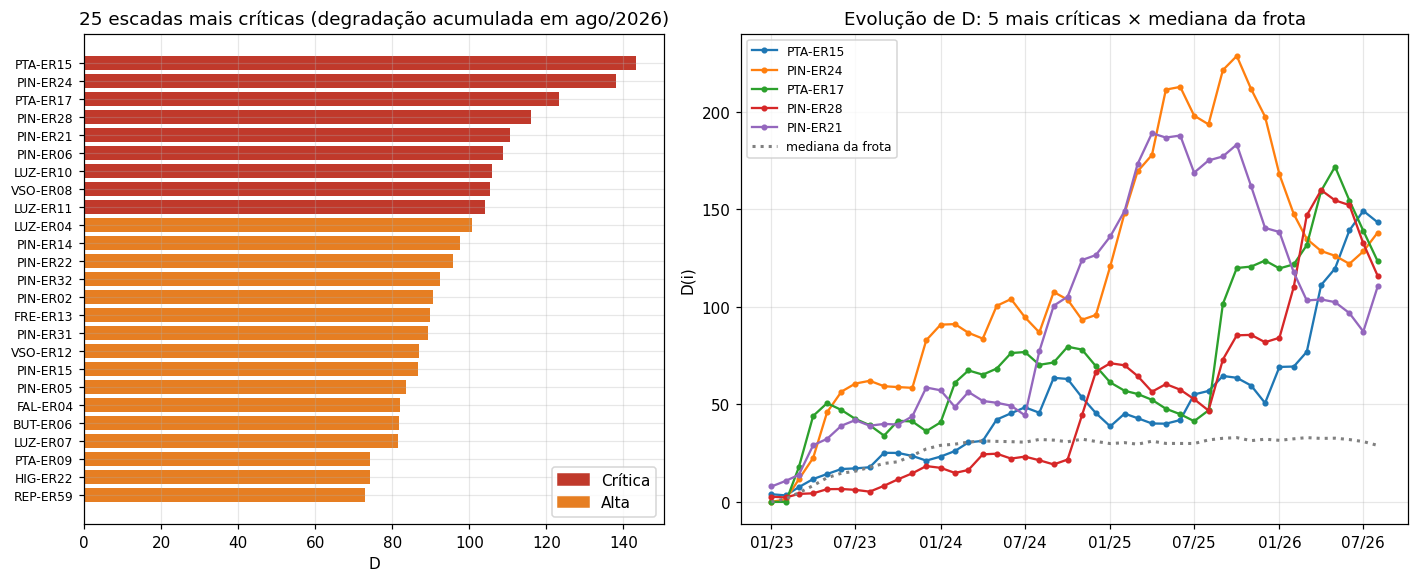

In [9]:
cores = {"Crítica": "#c0392b", "Alta": "#e67e22", "Média": "#f1c40f", "Baixa": "#27ae60"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 1.15]})
r = ranking.head(25).iloc[::-1]
ax[0].barh(r.cd_escada, r.criticidade, color=[cores[c] for c in r.classe])
ax[0].set(title="25 escadas mais críticas (degradação acumulada em ago/2026)", xlabel="D")
ax[0].tick_params(axis="y", labelsize=8)
from matplotlib.patches import Patch
ax[0].legend(handles=[Patch(color=cores[c], label=c) for c in ["Crítica", "Alta"]], loc="lower right")
datas = MESES.to_timestamp()
for cd in ranking.cd_escada.head(5):
    ax[1].plot(datas, serie_D[cd], marker=".", label=cd)
mediana = np.median(np.array(list(serie_D.values())), axis=0)
ax[1].plot(datas, mediana, color="grey", ls=":", lw=2, label="mediana da frota")
ax[1].set(title="Evolução de D: 5 mais críticas × mediana da frota", ylabel="D(i)")
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIGURAS / "ranking_criticidade.png", bbox_inches="tight"); plt.show()

**Interpretação.**

- **Onde está a degradação.** Das 9 escadas críticas, 4 ficam em Pinheiros, 2 na Paulista, 2 na Luz e 1 em Vila Sônia. São as estações de integração e de maior movimento da linha. Pinheiros também é a estação com mais escadas (32).
- **A 1ª do ranking não é a que mais falha.** A PTA-ER15 tem 75 falhas nos últimos 12 meses, contra 129 da PIN-ER24. Ela lidera porque somou 532 horas parada e está **piorando**: o termo de aceleração $\beta$ a coloca à frente de escadas com histórico pior, mas estável.
- **O que $D$ acrescenta a uma contagem simples.** A correlação com o número de falhas é alta (Spearman 0,89), mas o top 20 dos dois critérios só coincide em 14 escadas. A diferença está nas **paradas longas**. A PIN-ER15 tem só 25 falhas em 12 meses (128ª por contagem), mas ficou 3 823 horas parada por problema nas correntes do corrimão; pela degradação acumulada, ela sobe para a 18ª posição. Uma contagem simples esconderia esse caso.
- **Componentes recorrentes.** Rolete de degrau, sensores de presença e dispositivos de segurança aparecem repetidamente entre as mais críticas. O componente principal de cada escada orienta a ordem de serviço: o que verificar e quais peças levar.
- **Limites.** $D$ mede o **histórico de falhas**, não a condição física. Os pesos, $\alpha$ e $\beta$, foram definidos por critério técnico do squad e precisam ser validados com a engenharia da Motiva. Os sensores de vibração, temperatura e óleo previstos no projeto entrariam como novas parcelas da penalidade mensal, sem mudar o algoritmo.

---
## Parte 2 — Rede de estações como grafo

### 2.1 Modelagem

- **Vértices:** 19 locais das linhas operadas pela Motiva e 1 **base de manutenção** no Pátio Vila Sônia. São as 11 estações da Linha 4-Amarela (ViaQuatro) mais o Terminal Vila Sônia, que são os 12 locais com escadas no dataset, e 7 estações das Linhas 9-Esmeralda e 5-Lilás (ViaMobilidade), ligadas à Linha 4 por Pinheiros.
- **Ids = códigos do SAP:** os vértices da Linha 4 usam os mesmos códigos do campo Local de Instalação (PTA = Paulista, FRE = Oscar Freire, FAL = Faria Lima, MBI = São Paulo-Morumbi, TVS = Terminal Vila Sônia). É isso que liga cada escada do dataset a um vértice.
- **Arestas:** trechos entre estações, com peso em **minutos de deslocamento** da equipe. Trechos que começam em estações de integração (Pinheiros, Santo Amaro) já incluem a baldeação. Na 5-Lilás e na 9-Esmeralda, alguns trechos agregam estações intermediárias não modeladas.
- **Trechos rodoviários:** a equipe também pode sair da base de van. Esses trechos têm **poucas arestas, mas tempo maior** no trânsito, o que faz o BFS e o Dijkstra discordarem.
- **Estrutura:** lista de adjacência (`dict` de vértice para lista de vizinhos), grafo não direcionado.

Coordenadas e tempos são aproximados, adequados para o exercício e não para operação real.

In [10]:
def construir_lista_adjacencia(rede):
    """Monta a lista de adjacência não direcionada a partir do JSON da rede.

    Args:
        rede (dict): conteúdo de rede_estacoes.json.

    Returns:
        dict[str, list[tuple[str, float, str]]]: vértice -> [(vizinho, minutos, modo), ...].
    """
    adj = {v["id"]: [] for v in rede["vertices"]}
    for a in rede["arestas"]:
        adj[a["origem"]].append((a["destino"], a["minutos"], a["modo"]))
        adj[a["destino"]].append((a["origem"], a["minutos"], a["modo"]))
    for v in adj:
        adj[v].sort()
    return adj

ADJ = construir_lista_adjacencia(rede)
BASE = rede["base"]
COORD = {v["id"]: (v["lat"], v["lon"]) for v in rede["vertices"]}

for v, viz in ADJ.items():
    print(f"{v:>4} -> " + ", ".join(f"{u}({w} min, {m})" for u, w, m in viz))

sem_estacao = set(escadas.id_estacao) - set(ADJ)
print("\nEscadas ligadas a estações do grafo:", len(escadas) - len(sem_estacao), "de", len(escadas))
assert not sem_estacao, f"Escadas sem estação no grafo: {sem_estacao}"
print("Escadas por estação:", escadas.groupby("id_estacao").size().to_dict())

 LUZ -> REP(2 min, metro)
 REP -> HIG(2 min, metro), LUZ(2 min, metro)
 HIG -> PTA(2 min, metro), REP(2 min, metro)
 PTA -> BASE(35 min, rodovia), FRE(2 min, metro), HIG(2 min, metro)
 FRE -> FRA(2 min, metro), PTA(2 min, metro)
 FRA -> FAL(2 min, metro), FRE(2 min, metro)
 FAL -> FRA(2 min, metro), PIN(2 min, metro)
 PIN -> BUT(2 min, metro), CJD(9 min, trem), FAL(2 min, metro)
 BUT -> BASE(14 min, rodovia), MBI(3 min, metro), PIN(2 min, metro)
 MBI -> BUT(3 min, metro), VSO(3 min, metro)
 VSO -> BASE(6 min, rodovia), MBI(3 min, metro), TVS(3 min, a pé)
 TVS -> VSO(3 min, a pé)
 CJD -> PIN(9 min, trem), VOL(3 min, trem)
 VOL -> BER(3 min, trem), CJD(3 min, trem)
 BER -> SAM(9 min, trem), VOL(3 min, trem)
 SAM -> BASE(25 min, rodovia), BER(9 min, trem), CBE(15 min, metro)
 CBE -> MOE(4 min, metro), SAM(15 min, metro)
 MOE -> CBE(4 min, metro), SCZ(6 min, metro)
 SCZ -> MOE(6 min, metro)
BASE -> BUT(14 min, rodovia), PTA(35 min, rodovia), SAM(25 min, rodovia), VSO(6 min, rodovia)

Escad

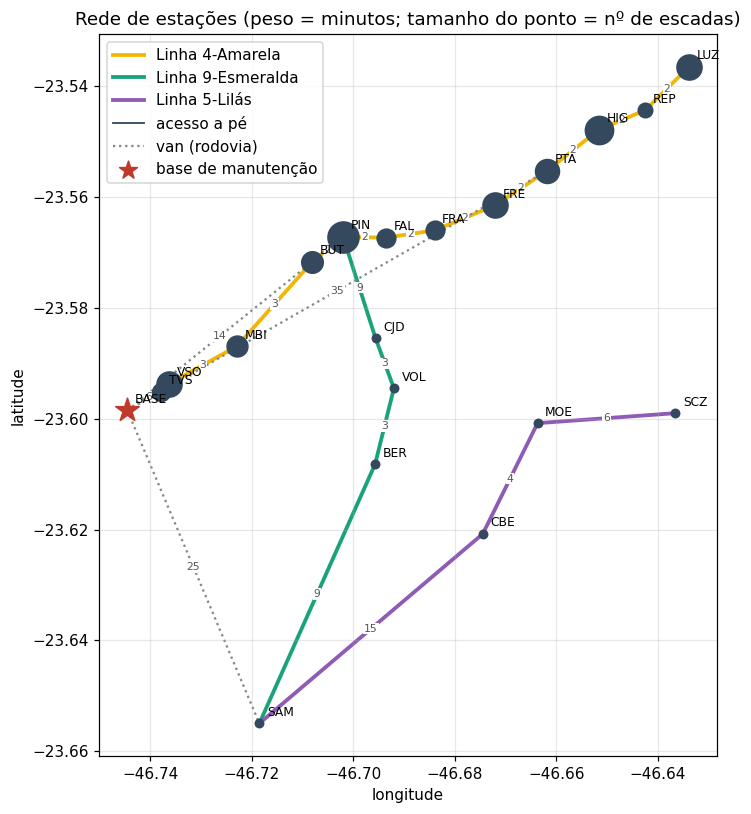

In [11]:
estilo = {"4-Amarela": dict(color="#f2b705", lw=2.5, ls="-"), "9-Esmeralda": dict(color="#1aa37a", lw=2.5, ls="-"),
          "5-Lilás": dict(color="#8e5bb5", lw=2.5, ls="-"), "acesso": dict(color="#34495e", lw=1.2, ls="-"),
          "rodovia": dict(color="#7f8c8d", lw=1.5, ls=":")}
fig, ax = plt.subplots(figsize=(9, 7.5))
for a in rede["arestas"]:
    (y1, x1), (y2, x2) = COORD[a["origem"]], COORD[a["destino"]]
    ax.plot([x1, x2], [y1, y2], **estilo[a["linha"]], zorder=1)
    ax.text((x1 + x2) / 2, (y1 + y2) / 2, f'{a["minutos"]}', fontsize=7, color="#555",
            ha="center", va="center", bbox=dict(fc="white", ec="none", pad=0.5), zorder=2)
qtd = escadas.groupby("id_estacao").size()
for v in rede["vertices"]:
    y, x = v["lat"], v["lon"]
    if v["id"] == BASE:
        ax.scatter(x, y, s=260, marker="*", color="#c0392b", zorder=3)
    else:
        ax.scatter(x, y, s=30 + 12 * qtd.get(v["id"], 0), color="#34495e", zorder=3)
    ax.annotate(v["id"], (x, y), xytext=(5, 5), textcoords="offset points", fontsize=8)
for nome, e in estilo.items():
    ax.plot([], [], **e, label={"rodovia": "van (rodovia)", "acesso": "acesso a pé"}.get(nome, f"Linha {nome}"))
ax.scatter([], [], marker="*", s=150, color="#c0392b", label="base de manutenção")
ax.legend(loc="upper left"); ax.set(title="Rede de estações (peso = minutos; tamanho do ponto = nº de escadas)",
                                    xlabel="longitude", ylabel="latitude")
ax.set_aspect(1 / math.cos(math.radians(-23.58)))
plt.tight_layout(); plt.savefig(FIGURAS / "rede_estacoes.png", bbox_inches="tight"); plt.show()

### 2.2 BFS (menos trechos) e Dijkstra (menor tempo)

- **BFS** explora o grafo em camadas e encontra o caminho com **menos arestas**, ignorando os pesos. Complexidade $O(V + E)$.
- **Dijkstra** usa uma fila de prioridade (heap) para sempre expandir o vértice de menor tempo acumulado e encontra o caminho de **menor tempo**. Complexidade $O((V + E)\log V)$.
- Os dois guardam o **predecessor** de cada vértice, e `reconstruir_rota` volta do destino até a origem para montar o caminho.

In [12]:
def bfs(adj, origem):
    """Busca em largura a partir da origem.

    Args:
        adj (dict): lista de adjacência.
        origem (str): vértice inicial.

    Returns:
        tuple[dict, dict]: (trechos até cada vértice, predecessor de cada vértice).
    """
    trechos, pai = {origem: 0}, {origem: None}
    fila = deque([origem])
    while fila:
        v = fila.popleft()
        for u, _, _ in adj[v]:
            if u not in trechos:
                trechos[u] = trechos[v] + 1
                pai[u] = v
                fila.append(u)
    return trechos, pai


def dijkstra(adj, origem, destino=None):
    """Menor tempo a partir da origem (Dijkstra com heap).

    Args:
        adj (dict): lista de adjacência com pesos em minutos.
        origem (str): vértice inicial.
        destino (str, opcional): se informado, para ao fechar o destino.

    Returns:
        tuple[dict, dict, int]: (tempo até cada vértice, predecessor, vértices expandidos).
    """
    dist, pai = {origem: 0.0}, {origem: None}
    heap, fechados, expandidos = [(0.0, origem)], set(), 0
    while heap:
        d, v = heapq.heappop(heap)
        if v in fechados:
            continue
        fechados.add(v); expandidos += 1
        if v == destino:
            break
        for u, w, _ in adj[v]:
            nd = d + w
            if nd < dist.get(u, math.inf):
                dist[u], pai[u] = nd, v
                heapq.heappush(heap, (nd, u))
    return dist, pai, expandidos


def reconstruir_rota(pai, origem, destino):
    """Reconstrói o caminho origem -> destino seguindo os predecessores.

    Returns:
        list[str]: vértices do caminho (vazia se o destino não for alcançável).
    """
    if destino not in pai:
        return []
    rota, v = [], destino
    while v is not None:
        rota.append(v); v = pai[v]
    rota.reverse()
    return rota if rota[0] == origem else []


def tempo_rota(adj, rota):
    """Soma dos minutos dos trechos de uma rota."""
    return sum(next(w for u, w, _ in adj[a] if u == b) for a, b in zip(rota, rota[1:]))


trechos_bfs, pai_bfs = bfs(ADJ, BASE)
dist_dij, pai_dij, _ = dijkstra(ADJ, BASE)

linhas = []
for v in sorted(ADJ, key=lambda x: dist_dij[x]):
    if v == BASE:
        continue
    rb, rd = reconstruir_rota(pai_bfs, BASE, v), reconstruir_rota(pai_dij, BASE, v)
    linhas.append({"estação": nomes_est[v], "rota BFS": " → ".join(rb), "trechos BFS": len(rb) - 1,
                   "min BFS": tempo_rota(ADJ, rb), "rota Dijkstra": " → ".join(rd),
                   "trechos Dijkstra": len(rd) - 1, "min Dijkstra": dist_dij[v]})
rotas = pd.DataFrame(linhas)
rotas["ganho (min)"] = rotas["min BFS"] - rotas["min Dijkstra"]
display(rotas)
dif = rotas[rotas["ganho (min)"] > 0]
print(f"Estações em que o BFS escolhe uma rota mais lenta: {len(dif)} de {len(rotas)}; "
      f"ganho médio do Dijkstra nelas: {dif['ganho (min)'].mean():.1f} min; máximo: {dif['ganho (min)'].max():.0f} min")

,estação,rota BFS,trechos BFS,min BFS,rota Dijkstra,trechos Dijkstra,min Dijkstra,ganho (min)
0,Vila Sônia,BASE → VSO,1,6,BASE → VSO,1,6.0,0.0
1,São Paulo-Morumbi,BASE → BUT → MBI,2,17,BASE → VSO → MBI,2,9.0,8.0
2,Terminal Vila Sônia,BASE → VSO → TVS,2,9,BASE → VSO → TVS,2,9.0,0.0
3,Butantã,BASE → BUT,1,14,BASE → VSO → MBI → BUT,3,12.0,2.0
4,Pinheiros,BASE → BUT → PIN,2,16,BASE → VSO → MBI → BUT → PIN,4,14.0,2.0
5,Faria Lima,BASE → BUT → PIN → FAL,3,18,BASE → VSO → MBI → BUT → PIN → FAL,5,16.0,2.0
6,Fradique Coutinho,BASE → PTA → FRE → FRA,3,39,BASE → VSO → MBI → BUT → PIN → FAL → FRA,6,18.0,21.0
7,Oscar Freire,BASE → PTA → FRE,2,37,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE,7,20.0,17.0
8,Paulista,BASE → PTA,1,35,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA,8,22.0,13.0
9,Cidade Jardim,BASE → BUT → PIN → CJD,3,25,BASE → VSO → MBI → BUT → PIN → CJD,5,23.0,2.0


Estações em que o BFS escolhe uma rota mais lenta: 13 de 19; ganho médio do Dijkstra nelas: 9.4 min; máximo: 21 min


**Interpretação.**

- Em 13 das 19 estações o BFS escolhe uma rota mais lenta (em média 9,4 min a mais, até 21 min). Nas estações da Linha 4 perto da Paulista, o **BFS escolhe a van** (BASE → PTA), porque é um único trecho, mas ela leva 35 minutos no trânsito; o **Dijkstra prefere o metrô** desde Vila Sônia, com mais trechos e bem menos tempo (22 min até a Paulista). É a diferença entre "menos trechos" e "menor tempo".
- Entre caminhos com o mesmo número de trechos, o BFS fica com o primeiro que encontra, sem olhar o tempo: para São Paulo-Morumbi ele vai pela van até o Butantã (17 min) em vez da van até Vila Sônia (9 min).
- Quando a van também é a opção mais rápida, como para Santo Amaro (25 min de van contra cerca de 38 min de metrô e trem), os dois algoritmos concordam.
- Para o planejamento de manutenção o critério correto é o **tempo**, por isso o `planejar_turno` usa Dijkstra. O BFS serve como referência de quantas baldeações e trocas de modal a rota exige.

---
## Parte 3 — Otimização de rotas com A*

### 3.1 Heurística

O A\* expande primeiro os vértices com menor $f(n) = g(n) + h(n)$, em que $g$ é o tempo já gasto e $h$ uma **estimativa do tempo restante**. Usamos:

$$
h(n) = \frac{\text{distância em linha reta}(n,\ \text{destino})}{v_{\max}}, \qquad
v_{\max} = \max_{(a,b) \in E} \frac{\text{distância em linha reta}(a,b)}{\text{minutos}(a,b)}
$$

A distância em linha reta é calculada pela fórmula de haversine sobre as coordenadas das estações, e $v_{\max}$ é a **maior velocidade efetiva** observada em algum trecho da própria rede.

**Por que é admissível (nunca superestima):** em qualquer trecho, $\text{minutos}(a,b) \ge \text{dist}(a,b)/v_{\max}$ pela definição de $v_{\max}$. Somando ao longo de qualquer caminho de $n$ até o destino e usando a desigualdade triangular (a linha reta é o menor percurso), o tempo real é sempre $\ge \text{dist}(n,\text{destino})/v_{\max} = h(n)$. **Consistência** sai do mesmo argumento aplicado a um único trecho: $h(a) \le \text{minutos}(a,b) + h(b)$. Com $h$ consistente, o A\* retorna o caminho ótimo sem reabrir vértices.

Usar a velocidade máxima da própria rede, em vez de um valor fixo como 80 km/h, deixa $h$ o mais informativa possível sem perder a garantia. Para comparar, testamos também $h_{80}$ (80 km/h fixos, mais fraca) e $h = 0$ (que transforma o A\* no próprio Dijkstra).

In [13]:
def haversine_km(a, b):
    """Distância em linha reta (km) entre dois vértices, pelas coordenadas."""
    (la1, lo1), (la2, lo2) = COORD[a], COORD[b]
    la1, lo1, la2, lo2 = map(math.radians, (la1, lo1, la2, lo2))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371.0 * math.asin(math.sqrt(h))

VMAX = max(haversine_km(a["origem"], a["destino"]) / a["minutos"] for a in rede["arestas"])  # km/min
trecho_vmax = max(rede["arestas"], key=lambda a: haversine_km(a["origem"], a["destino"]) / a["minutos"])
print(f"v_max da rede = {VMAX:.3f} km/min = {VMAX * 60:.1f} km/h "
      f"(trecho {trecho_vmax['origem']}–{trecho_vmax['destino']})")


def heuristica_rede(destino):
    """h(n) = distância em linha reta até o destino / v_max da rede (minutos)."""
    return lambda n: haversine_km(n, destino) / VMAX

def heuristica_80kmh(destino):
    """h(n) com velocidade fixa de 80 km/h (admissível, porém mais fraca)."""
    return lambda n: haversine_km(n, destino) / (80 / 60)

def heuristica_zero(destino):
    """h(n) = 0: o A* se reduz ao Dijkstra."""
    return lambda n: 0.0


def a_estrela(adj, origem, destino, h):
    """Busca A* do caminho de menor tempo.

    Args:
        adj (dict): lista de adjacência com pesos em minutos.
        origem (str): vértice inicial.
        destino (str): vértice final.
        h (callable): heurística h(n) em minutos, admissível e consistente.

    Returns:
        tuple[float, list[str], int]: (tempo mínimo, rota, vértices expandidos).
    """
    g, pai = {origem: 0.0}, {origem: None}
    heap, fechados, expandidos = [(h(origem), 0.0, origem)], set(), 0
    while heap:
        _, gv, v = heapq.heappop(heap)
        if v in fechados:
            continue
        fechados.add(v); expandidos += 1
        if v == destino:
            return gv, reconstruir_rota(pai, origem, destino), expandidos
        for u, w, _ in adj[v]:
            ng = gv + w
            if ng < g.get(u, math.inf):
                g[u], pai[u] = ng, v
                heapq.heappush(heap, (ng + h(u), ng, u))
    return math.inf, [], expandidos


# Verificação numérica de admissibilidade e consistência, para todos os pares (n, destino)
viol_adm = viol_cons = 0
for destino in ADJ:
    real, _, _ = dijkstra(ADJ, destino)
    h = heuristica_rede(destino)
    viol_adm += sum(h(n) > real[n] + 1e-9 for n in ADJ)
    viol_cons += sum(h(a) > w + h(b) + 1e-9 for a in ADJ for b, w, _ in ADJ[a])
print("Violações de admissibilidade:", viol_adm, "| violações de consistência:", viol_cons)

v_max da rede = 0.755 km/min = 45.3 km/h (trecho BUT–MBI)
Violações de admissibilidade: 0 | violações de consistência: 0


### 3.2 A\* comparado ao Dijkstra na rede de estações

Para uma comparação justa, o Dijkstra também para assim que fecha o destino. Medimos o tempo mínimo encontrado, os **vértices expandidos** e o tempo de execução (mediana de 200 repetições) da base até cada estação.

In [14]:
def medir_us(func, rep=200):
    """Mediana do tempo de execução de func() em microssegundos."""
    t = []
    for _ in range(rep):
        t0 = time.perf_counter(); func(); t.append(time.perf_counter() - t0)
    return 1e6 * float(np.median(t))

linhas = []
for destino in [v for v in ADJ if v != BASE]:
    d_dij, _, exp_dij = dijkstra(ADJ, BASE, destino)
    c_a, rota_a, exp_a = a_estrela(ADJ, BASE, destino, heuristica_rede(destino))
    _, _, exp_80 = a_estrela(ADJ, BASE, destino, heuristica_80kmh(destino))
    linhas.append({"destino": destino, "min Dijkstra": d_dij[destino], "min A*": c_a,
                   "exp Dijkstra": exp_dij, "exp A* (v_max)": exp_a, "exp A* (80 km/h)": exp_80,
                   "µs Dijkstra": medir_us(lambda: dijkstra(ADJ, BASE, destino)),
                   "µs A*": medir_us(lambda: a_estrela(ADJ, BASE, destino, heuristica_rede(destino)))})
astar_rede = pd.DataFrame(linhas)
display(astar_rede.round(1))
print("Mesmo tempo ótimo em todos os destinos:", np.allclose(astar_rede["min Dijkstra"], astar_rede["min A*"]))
tot = astar_rede[["exp Dijkstra", "exp A* (v_max)", "exp A* (80 km/h)"]].sum()
print(f"Expansões totais — Dijkstra: {tot.iloc[0]} | A* v_max: {tot.iloc[1]} ({100 * (1 - tot.iloc[1] / tot.iloc[0]):.0f}% a menos)"
      f" | A* 80 km/h: {tot.iloc[2]} ({100 * (1 - tot.iloc[2] / tot.iloc[0]):.0f}% a menos)")

,destino,min Dijkstra,min A*,exp Dijkstra,exp A* (v_max),exp A* (80 km/h),µs Dijkstra,µs A*
0,LUZ,28.0,28.0,16,13,13,10.7,27.9
1,REP,26.0,26.0,14,12,12,9.3,21.5
2,HIG,24.0,24.0,12,11,11,8.4,19.8
3,PTA,22.0,22.0,10,10,10,7.1,18.2
4,FRE,20.0,20.0,9,9,9,8.1,17.1
5,FRA,18.0,18.0,8,8,8,6.0,15.7
6,FAL,16.0,16.0,7,6,7,5.2,14.0
7,PIN,14.0,14.0,6,5,6,4.5,11.5
8,BUT,12.0,12.0,5,4,5,3.6,9.7
9,MBI,9.0,9.0,3,3,3,2.7,8.4


Mesmo tempo ótimo em todos os destinos: True
Expansões totais — Dijkstra: 209 | A* v_max: 180 (14% a menos) | A* 80 km/h: 189 (10% a menos)


### 3.3 Escalabilidade: uma malha urbana maior

A rede do exercício tem só 20 vértices, então qualquer algoritmo termina em microssegundos. Para ver como a diferença cresce, geramos uma **malha urbana sintética** de 60 × 60 cruzamentos (3 600 vértices, espaçamento de 0,5 km) com tempos de trecho entre 1× e 2,5× o tempo a 30 km/h (trânsito variável). A heurística é a mesma ideia: distância em linha reta dividida pela maior velocidade efetiva da malha. Rodamos 40 pares origem–destino aleatórios.

Mesmo tempo ótimo em todos os pares: True


,exp Dijkstra,exp A*,ms Dijkstra,ms A*
mean,1807.8,946.8,2.8,1.9
median,1802.5,801.0,2.6,1.5


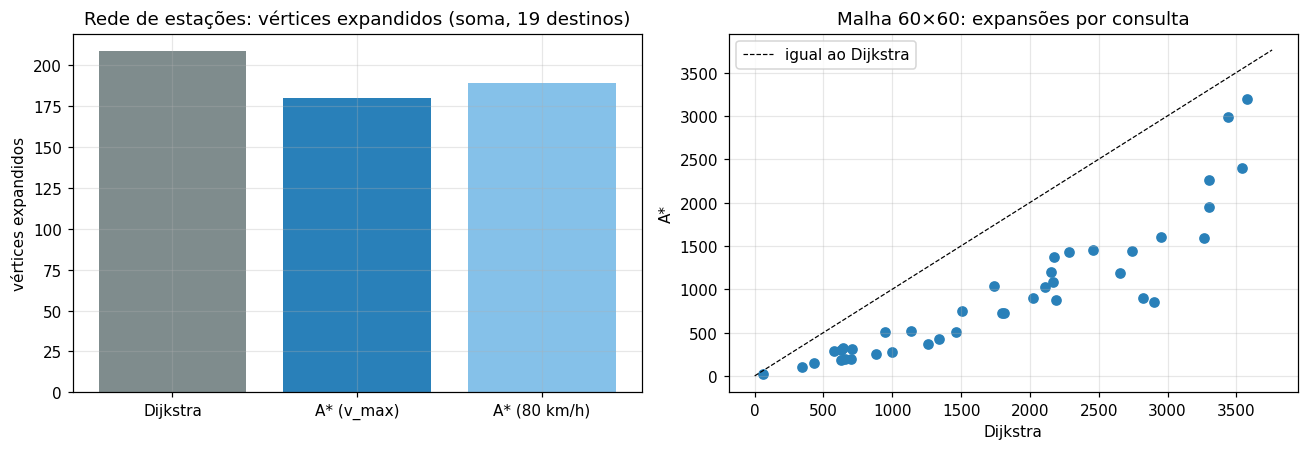

In [15]:
def malha_urbana(lado=60, passo_km=0.5, semente=3):
    """Cria uma malha urbana sintética (lista de adjacência + coordenadas em km)."""
    rnd = random.Random(semente)
    coord = {(i, j): (i * passo_km, j * passo_km) for i in range(lado) for j in range(lado)}
    adj = {v: [] for v in coord}
    for (i, j) in coord:
        for di, dj in ((1, 0), (0, 1)):
            u = (i + di, j + dj)
            if u in coord:
                w = passo_km / 0.5 * rnd.uniform(1.0, 2.5)   # 0,5 km/min = 30 km/h
                adj[(i, j)].append((u, w, "rua")); adj[u].append(((i, j), w, "rua"))
    return adj, coord

ADJ_M, COORD_M = malha_urbana()
VMAX_M = max(math.dist(COORD_M[a], COORD_M[b]) / w for a in ADJ_M for b, w, _ in ADJ_M[a])
rnd = random.Random(11)
pares = [(rnd.choice(list(ADJ_M)), rnd.choice(list(ADJ_M))) for _ in range(40)]

res = []
for o, d in pares:
    hm = lambda n, d=d: math.dist(COORD_M[n], COORD_M[d]) / VMAX_M
    dd, _, ed = dijkstra(ADJ_M, o, d)
    ca, _, ea = a_estrela(ADJ_M, o, d, hm)
    res.append({"min Dijkstra": dd[d], "min A*": ca, "exp Dijkstra": ed, "exp A*": ea,
                "ms Dijkstra": medir_us(lambda: dijkstra(ADJ_M, o, d), 5) / 1e3,
                "ms A*": medir_us(lambda: a_estrela(ADJ_M, o, d, hm), 5) / 1e3})
malha = pd.DataFrame(res)
print("Mesmo tempo ótimo em todos os pares:", np.allclose(malha["min Dijkstra"], malha["min A*"]))
resumo = malha[["exp Dijkstra", "exp A*", "ms Dijkstra", "ms A*"]].agg(["mean", "median"]).round(1)
display(resumo)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].bar(["Dijkstra", "A* (v_max)", "A* (80 km/h)"], tot.values, color=["#7f8c8d", "#2980b9", "#85c1e9"])
ax[0].set(title="Rede de estações: vértices expandidos (soma, 19 destinos)", ylabel="vértices expandidos")
ax[1].scatter(malha["exp Dijkstra"], malha["exp A*"], color="#2980b9")
lim = malha["exp Dijkstra"].max() * 1.05
ax[1].plot([0, lim], [0, lim], "k--", lw=0.8, label="igual ao Dijkstra")
ax[1].set(title="Malha 60×60: expansões por consulta", xlabel="Dijkstra", ylabel="A*")
ax[1].legend()
plt.tight_layout(); plt.savefig(FIGURAS / "astar_vs_dijkstra.png", bbox_inches="tight"); plt.show()

**Interpretação.**

- **Mesmo resultado, menos trabalho.** O A\* encontrou exatamente o mesmo tempo mínimo que o Dijkstra em todos os destinos, como garante a heurística admissível e consistente (verificada numericamente acima, sem nenhuma violação).
- **Na rede das estações o ganho em expansões é modesto e não vira ganho de tempo.** O A\* expande 14% menos vértices no total (180 contra 209), com o maior efeito nos destinos da Linha 9 (Santo Amaro: 6 expansões contra 13), porque deixa de explorar o lado da rede que se afasta do destino. Mesmo assim, em tempo de relógio ele leva cerca de 2 vezes mais microssegundos: calcular a haversine em cada vértice custa mais do que expandir os poucos vértices economizados em um grafo de 20 vértices.
- **A heurística mais informada ganha.** Usar a $v_{\max}$ da própria rede expande menos que os 80 km/h fixos, porque estima o tempo restante com mais precisão sem deixar de ser admissível.
- **Na malha de 3 600 vértices o A\* mostra a vantagem real:** na mediana expande 801 vértices contra 1 803 do Dijkstra (55% a menos) e também roda mais rápido (veja a tabela acima; os milissegundos variam um pouco a cada execução, as expansões não). O Dijkstra cresce em círculo a partir da origem, enquanto o A\* avança na direção do alvo.
- **Conclusão para o SafeStair:** com a rede atual, Dijkstra a partir da base (uma única execução calcula todas as rotas) é suficiente e mais simples. O A\* passa a compensar quando a rede incluir todas as estações e acessos viários das concessões da Motiva e as consultas forem ponto a ponto, como no replanejamento de um técnico já em campo.

---
## Parte 4 — Plano de manutenção: `planejar_turno(base, horas)`

**Regras:**

1. Entram no plano as escadas de classe **Crítica e Alta** (39 escadas, os 20% mais degradados); as demais seguem em monitoramento.
2. **Prioridade por classe:** nenhuma escada de uma classe é atendida antes das que cabem no turno da classe acima.
3. **Dentro da mesma classe:** primeiro as outras escadas da estação onde a equipe já está (deslocamento zero); depois, a de maior criticidade, onde quer que esteja. O caminho até ela é o de menor tempo (Dijkstra).
4. Uma escada só entra se o deslocamento + o serviço + **o retorno à base** ainda couberem no turno. Se não couber, fica como pendente e o algoritmo tenta a próxima.
5. **Tempo de serviço vindo dos dados:** para cada escada, o percentil 75 da duração das paradas dela nos últimos 12 meses, limitado entre 30 e 240 minutos. Escadas que costumam ficar paradas mais tempo recebem mais tempo no turno.

Os tempos entre estações vêm de uma tabela de menores tempos (Dijkstra a partir de cada vértice), e as rotas são reconstruídas com `reconstruir_rota`.

In [16]:
ORDEM_CLASSES = ["Crítica", "Alta"]

# Tempo de serviço de cada escada = percentil 75 das paradas dela nos últimos 12 meses, entre 30 e 240 min
TEMPO_SERVICO = (ult12.groupby("cd_escada").horas_parada.quantile(0.75).mul(60).clip(30, 240).round()
                 .reindex(ranking.cd_escada).fillna(60))
ranking["servico_min"] = ranking.cd_escada.map(TEMPO_SERVICO)

# Menores tempos e predecessores de todos para todos (uma execução de Dijkstra por vértice)
TODOS_DIJ = {v: dijkstra(ADJ, v)[:2] for v in ADJ}


def planejar_turno(base, horas, ranking=None, adj=None, inicio="08:00"):
    """Indica quais escadas atender no turno, em que ordem e por qual caminho.

    Args:
        base (str): id do vértice de onde a equipe sai e para onde volta (ex.: 'BASE').
        horas (float): duração do turno em horas.
        ranking (pd.DataFrame, opcional): ranking de criticidade (padrão: o calculado na Parte 1).
        adj (dict, opcional): lista de adjacência (padrão: a rede de estações).
        inicio (str): horário de início do turno, 'HH:MM'.

    Returns:
        tuple[pd.DataFrame, dict]: (plano de visitas em ordem, resumo do turno).
    """
    ranking = RANKING_PADRAO if ranking is None else ranking
    adj = ADJ if adj is None else adj
    tempos = TODOS_DIJ if adj is ADJ else {v: dijkstra(adj, v)[:2] for v in adj}
    orcamento = horas * 60
    h0, m0 = map(int, inicio.split(":"))
    relogio = lambda minutos: f"{(h0 * 60 + m0 + int(round(minutos))) // 60 % 24:02d}:{(m0 + int(round(minutos))) % 60:02d}"

    posicao, t, plano, pendentes = base, 0.0, [], []
    for classe in ORDEM_CLASSES:
        restantes = ranking[ranking.classe == classe].copy()
        while not restantes.empty:
            dist_atual = tempos[posicao][0]
            restantes["desloc"] = restantes.id_estacao.map(dist_atual)
            restantes["volta"] = restantes.id_estacao.map(lambda e: tempos[e][0][base])
            restantes["cabe"] = t + restantes.desloc + restantes.servico_min + restantes.volta <= orcamento
            viaveis = restantes[restantes.cabe]
            if viaveis.empty:
                pendentes += restantes.cd_escada.tolist()
                break
            prox = (viaveis.assign(outra_estacao=viaveis.desloc > 0)
                    .sort_values(["outra_estacao", "criticidade"], ascending=[True, False]).iloc[0])
            rota = reconstruir_rota(tempos[posicao][1], posicao, prox.id_estacao)
            chegada = t + prox.desloc
            plano.append({"ordem": len(plano) + 1, "escada": prox.cd_escada, "estação": prox.estacao,
                          "classe": classe, "criticidade": round(prox.criticidade, 1),
                          "componente": prox.componente_principal,
                          "rota": " → ".join(rota) if len(rota) > 1 else "(mesma estação)",
                          "desloc. (min)": prox.desloc, "chegada": relogio(chegada),
                          "serviço (min)": prox.servico_min, "término": relogio(chegada + prox.servico_min)})
            t = chegada + prox.servico_min
            posicao = prox.id_estacao
            restantes = restantes[restantes.cd_escada != prox.cd_escada]

    volta = tempos[posicao][0][base]
    rota_volta = reconstruir_rota(tempos[posicao][1], posicao, base)
    total = t + volta
    resumo = {"turno (min)": orcamento, "escadas atendidas": len(plano),
              "deslocamento (min)": sum(p["desloc. (min)"] for p in plano) + volta,
              "serviço (min)": sum(p["serviço (min)"] for p in plano),
              "retorno": " → ".join(rota_volta) + f" ({volta:.0f} min, chegada {relogio(total)})",
              "ocupação do turno": f"{100 * total / orcamento:.0f}%",
              "pendentes": pendentes}
    return pd.DataFrame(plano).set_index("ordem") if plano else pd.DataFrame(), resumo


RANKING_PADRAO = ranking.copy()
print("Escadas candidatas por classe:", ranking[ranking.classe.isin(ORDEM_CLASSES)].classe.value_counts().to_dict())
print("Tempo de serviço das candidatas (min):", ranking[ranking.classe.isin(ORDEM_CLASSES)].servico_min.describe().round(0).to_dict())

Escadas candidatas por classe: {'Alta': 30, 'Crítica': 9}
Tempo de serviço das candidatas (min): {'count': 39.0, 'mean': 109.0, 'std': 75.0, 'min': 34.0, '25%': 52.0, '50%': 75.0, '75%': 140.0, 'max': 240.0}


In [17]:
plano8, resumo8 = planejar_turno("BASE", 8)
print("TURNO DE 8 HORAS (início 08:00)")
display(plano8)
for k, v in resumo8.items():
    print(f"  {k}: {v}")

TURNO DE 8 HORAS (início 08:00)


,escada,estação,classe,criticidade,componente,rota,desloc. (min),chegada,serviço (min),término
ordem,,,,,,,,,,
1,PTA-ER15,Paulista,Crítica,143.3,PLACA PENTE MOVEL,BASE → VSO → MBI → BUT → PIN → FAL → FRA → FRE → PTA,22.0,08:22,230.0,12:12
2,PTA-ER17,Paulista,Crítica,123.4,PENTE DA PLACA PENTE,(mesma estação),0.0,12:12,51.0,13:03
3,PIN-ER24,Pinheiros,Crítica,138.1,SENSOR DE PRESENCA-VELOCIDAD-CJ.MOTO-RED,PTA → FRE → FRA → FAL → PIN,8.0,13:11,76.0,14:27
4,PIN-ER28,Pinheiros,Crítica,115.9,DISPOSITIVO DE SEGURANCA,(mesma estação),0.0,14:27,68.0,15:35


  turno (min): 480
  escadas atendidas: 4
  deslocamento (min): 44.0
  serviço (min): 425.0
  retorno: PIN → BUT → MBI → VSO → BASE (14 min, chegada 15:49)
  ocupação do turno: 98%
  pendentes: ['PIN-ER21', 'PIN-ER06', 'LUZ-ER10', 'VSO-ER08', 'LUZ-ER11', 'LUZ-ER04', 'PIN-ER14', 'PIN-ER22', 'PIN-ER32', 'PIN-ER02', 'FRE-ER13', 'PIN-ER31', 'VSO-ER12', 'PIN-ER15', 'PIN-ER05', 'FAL-ER04', 'BUT-ER06', 'LUZ-ER07', 'PTA-ER09', 'HIG-ER22', 'REP-ER59', 'LUZ-ER06', 'PIN-ER20', 'LUZ-ER09', 'BUT-ER05', 'PIN-ER16', 'BUT-ER09', 'PIN-ER30', 'PIN-ER04', 'HIG-ER24', 'BUT-ER08', 'FAL-ER09', 'LUZ-ER02', 'FRE-ER20', 'PIN-ER09']


In [18]:
comparativo = []
for horas in [4, 6, 8, 10, 12]:
    p, r = planejar_turno("BASE", horas)
    comparativo.append({"turno (h)": horas, "atendidas": r["escadas atendidas"],
                        "críticas atendidas": int((p.classe == "Crítica").sum()) if len(p) else 0,
                        "deslocamento (min)": r["deslocamento (min)"], "serviço (min)": r["serviço (min)"],
                        "ocupação": r["ocupação do turno"], "pendentes": len(r["pendentes"])})
display(pd.DataFrame(comparativo).set_index("turno (h)"))

plano4, resumo4 = planejar_turno("BASE", 4)
print("\nTURNO DE 4 HORAS")
display(plano4[["escada", "estação", "classe", "rota", "desloc. (min)", "chegada", "término"]])
print("Retorno:", resumo4["retorno"], "| pendentes:", resumo4["pendentes"])

,atendidas,críticas atendidas,deslocamento (min),serviço (min),ocupação,pendentes
turno (h),,,,,,
4,3,3,44.0,195.0,100%,36
6,2,2,44.0,281.0,90%,37
8,4,4,44.0,425.0,98%,35
10,5,5,44.0,545.0,98%,34
12,5,5,44.0,665.0,98%,34



TURNO DE 4 HORAS


,escada,estação,classe,rota,desloc. (min),chegada,término
ordem,,,,,,,
1,PIN-ER24,Pinheiros,Crítica,BASE → VSO → MBI → BUT → PIN,14.0,08:14,09:30
2,PIN-ER28,Pinheiros,Crítica,(mesma estação),0.0,09:30,10:38
3,PTA-ER17,Paulista,Crítica,PIN → FAL → FRA → FRE → PTA,8.0,10:46,11:37


Retorno: PTA → FRE → FRA → FAL → PIN → BUT → MBI → VSO → BASE (22 min, chegada 11:59) | pendentes: ['PTA-ER15', 'PIN-ER21', 'PIN-ER06', 'LUZ-ER10', 'VSO-ER08', 'LUZ-ER11', 'LUZ-ER04', 'PIN-ER14', 'PIN-ER22', 'PIN-ER32', 'PIN-ER02', 'FRE-ER13', 'PIN-ER31', 'VSO-ER12', 'PIN-ER15', 'PIN-ER05', 'FAL-ER04', 'BUT-ER06', 'LUZ-ER07', 'PTA-ER09', 'HIG-ER22', 'REP-ER59', 'LUZ-ER06', 'PIN-ER20', 'LUZ-ER09', 'BUT-ER05', 'PIN-ER16', 'BUT-ER09', 'PIN-ER30', 'PIN-ER04', 'HIG-ER24', 'BUT-ER08', 'FAL-ER09', 'LUZ-ER02', 'FRE-ER20', 'PIN-ER09']


**Interpretação.**

- **Coerência com o ranking:** no turno de 8 h a equipe atende 4 das 9 escadas críticas, começando pela PTA-ER15, 1ª do ranking. Nenhuma escada de classe Alta entra antes das críticas.
- **Agrupamento por estação:** na Paulista a equipe atende a PTA-ER15 e, em seguida, a PTA-ER17, sem deslocamento entre elas. Depois vai de metrô para Pinheiros (8 min), onde faz a PIN-ER24 e a PIN-ER28. No total são 44 minutos de deslocamento contra 425 de serviço.
- **Rotas do Dijkstra:** a ida à Paulista é de metrô desde Vila Sônia (22 min), e não pela van direta (35 min). A volta sai de Pinheiros pela Linha 4 até Vila Sônia e de lá de van até a base.
- **Tempo de serviço vindo dos dados:** a PTA-ER15 recebe 230 minutos porque as paradas dela costumam ser longas, enquanto a PTA-ER17 recebe 51. Com tempos fixos por classe, o plano ignoraria essa diferença.
- **Prioridade × quantidade:** o turno de 6 h atende menos escadas (2) que o de 4 h (3). Em 6 h passa a caber a PTA-ER15, a mais crítica, que sozinha ocupa quase 4 horas; em 4 h ela não cabe e a equipe faz três serviços menores. O plano prioriza a criticidade, não o número de escadas.
- **Gargalo:** com 9 escadas críticas e tempo de serviço mediano de 75 minutos entre as 39 candidatas, uma equipe por turno não dá conta nem das críticas. O dado indica a necessidade de duas equipes, ou de uma base avançada perto de Pinheiros e da Paulista.
- **Limites:** o algoritmo é guloso e não garante o máximo de escadas por turno; o problema exato é uma variação do *orienteering problem*, NP-difícil. O tempo de serviço histórico inclui a espera pelo técnico, e os tempos de trecho não variam com o horário.

## Conclusões

| Experimento | Resultado principal |
|---|---|
| Dataset | 27 200 falhas corretivas reais de 197 escadas da Linha 4 (jan/2023 a ago/2026), com recorte justificado pela mudança no registro em 2023. |
| Degradação (3 versões) | Resultados idênticos. A recursiva pura é exponencial: 1,8 bilhão de chamadas por escada na série de 44 meses. Memoizada e tabulação são lineares, e a tabulação foi adotada por não depender da pilha. |
| Ranking | 9 críticas, concentradas em Pinheiros, Paulista e Luz. A degradação acumulada destaca paradas longas e tendência de piora que uma contagem simples esconde. |
| BFS × Dijkstra | Em 13 de 19 estações o BFS escolhe uma rota mais lenta (até 21 min a mais); o planejamento usa Dijkstra. |
| A\* × Dijkstra | Mesmos tempos ótimos. Faz 14% menos expansões na rede de 20 vértices, mas sem ganho de tempo; faz 55% menos expansões na malha de 3 600 vértices, onde também roda mais rápido. |
| `planejar_turno` | Atende as críticas em ordem de criticidade, agrupa por estação, usa o tempo de reparo histórico de cada escada e respeita o turno e o retorno à base. |